# Projet de Machine Learning : battre la marche aléatoire avec KNN

**Projet F8 · Cours Algorithmes de Machine Learning** · Version corrigée sur le modèle de l'étude de cas UCI 222
**Algorithme principal :** 9, KNN (K plus proches voisins, classification) · **Données :** S&P 500, série `SP500` de FRED
**Auteur(s) :** à compléter · **Enseignant(e) :** à compléter

Ce notebook reproduit tout le projet, dans l'ordre du rapport : introduction, état de l'art, travaux liés, données, exploration, préparation, algorithme, protocole, résultats, discussion, conclusion, références et annexes. Il télécharge lui-même les données : il suffit de lancer **Exécution > Tout exécuter** (1 à 2 minutes).

> **À propos des chiffres commentés.** Les paragraphes intitulés *Lecture*, *Analyse* ou *Discussion* sont **générés par le code** à partir des résultats de votre exécution : ils ne contiennent aucun chiffre écrit à la main. Selon la version de scikit-learn et la date de téléchargement (FRED fournit les dix dernières années), les valeurs peuvent varier ; le texte suit toujours ce que les cellules calculent.

**Sommaire**
0. Configuration
1. Introduction
2. État de l'art
3. Travaux liés
4. Jeu de données
5. Exploration
6. Préparation
7. Algorithme
8. Protocole expérimental
9. Résultats
10. Discussion des résultats
11. Conclusion
12. Références et citations
13. Annexes

## 0. Configuration

In [1]:
# Facultatif : pour retrouver exactement la version de scikit-learn de l'exécution de référence,
# décommentez la ligne suivante, exécutez-la, puis relancez tout le notebook.
# !pip -q install scikit-learn==1.9.1

import platform, json, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
from sklearn.inspection import permutation_importance

GRAINE = 42
np.random.seed(GRAINE)
BASE = Path('projet_sp500')
DONNEES = BASE / 'data' / 'raw'
FIGURES = BASE / 'figures'
for dossier in (DONNEES, FIGURES):
    dossier.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'font.size': 9})
virgule = FuncFormatter(lambda v, pos: '{:g}'.format(v).replace('.', ','))

def fr(x, d=1):
    """Nombre au format français (virgule décimale)."""
    return '{:.{d}f}'.format(x, d=d).replace('.', ',')

def pct(x, d=1):
    """Proportion (0 à 1) affichée en pourcentage au format français."""
    return fr(x * 100, d) + ' %'

def ecrire(texte):
    """Affiche un texte Markdown (utilisé pour les lectures calculées)."""
    display(Markdown(texte))

R = {}  # tous les résultats chiffrés, enregistrés à la fin
print('Python', platform.python_version(), '| pandas', pd.__version__, '| NumPy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Python 3.13.18 | pandas 2.2.3 | NumPy 2.4.6 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 1. Introduction

**Contexte.** Sur les marchés financiers, il est difficile de prévoir la direction future des cours : les variations quotidiennes comportent une forte composante aléatoire. Si les prix suivaient une marche aléatoire, aucune information passée ne permettrait de prévoir le lendemain mieux que le hasard. L'objectif est de déterminer si un algorithme de Machine Learning peut exploiter l'historique des rendements et de la volatilité pour améliorer la prévision de la direction du marché.

**Problématique.** L'algorithme K-Nearest Neighbors (KNN), utilisant les rendements historiques et la volatilité passée du S&P 500, permet-il de prédire la hausse ou la baisse du marché le jour suivant avec une performance supérieure à celle d'une stratégie de référence naïve ?

**Objectif mesurable.** Sur la période de test (les 20 % de séances les plus récentes, jamais utilisées pendant le réglage), obtenir une *balanced accuracy* supérieure d'au moins **deux points de pourcentage** à celle de la meilleure référence naïve.

**Nature du problème.** Classification binaire :

- classe 1 : le marché monte le jour suivant (rendement logarithmique strictement positif) ;
- classe 0 : le marché baisse ou ne monte pas le jour suivant.

Les deux classes sont proches de l'équilibre, mais pas égales : les séances de hausse sont un peu plus nombreuses. L'*accuracy* récompenserait alors un modèle qui prédit toujours « hausse » ; la *balanced accuracy* (moyenne du rappel de chaque classe) vaut exactement 0,5 pour un tel modèle, ce qui en fait une métrique plus exigeante [8].

## 2. État de l'art

Prévoir la direction d'un indice boursier est un problème de classification sur série temporelle. L'hypothèse d'efficience des marchés et la marche aléatoire constituent la référence théorique : si les prix intègrent toute l'information disponible, les rendements passés n'aident pas à prévoir les suivants [2]. Des études empiriques trouvent pourtant de faibles dépendances, par exemple une légère autocorrélation des rendements hebdomadaires [3], mais la plupart des prédicteurs proposés échouent à battre une prévision naïve *hors échantillon* [4]. Les méthodes non linéaires d'apprentissage automatique améliorent parfois la prévision, avec des gains modestes [5]. Le KNN classe une observation selon la majorité de ses plus proches voisins dans l'historique [6]. Enfin, quand le contexte de marché change, les relations apprises sur le passé se dégradent : c'est la dérive conceptuelle [11].

| Approche | Principe | Atouts | Limites | Réf. |
| --- | --- | --- | --- | --- |
| Marche aléatoire, référence naïve | Aucune information utile dans le passé : on prédit la classe majoritaire ou la direction de la veille | Aucun paramètre, difficile à battre | Ignore toute structure éventuelle | [2], cette étude |
| Régression logistique | Combinaison linéaire des variables, transformée en probabilité | Interprétable, robuste | Effets linéaires sur la log-cote | [7] |
| KNN | Vote des *k* séances passées les plus semblables | Non paramétrique, simple, sans hypothèse de linéarité | Sensible à *k*, à la distance et à l'échelle ; peu robuste au bruit | [6] |
| Arbres, réseaux de neurones | Relations non linéaires et interactions apprises | Très flexibles | Réglages et calcul exigeants, risque de surapprentissage | [5] |

## 3. Travaux liés

| Travail | Données | Méthode | Résultat principal | Différence avec cette étude |
| --- | --- | --- | --- | --- |
| Lo et MacKinlay, 1988 [3] | Rendements hebdomadaires d'indices d'actions américains, années 1960 à 1980 | Test de rapport de variances | La marche aléatoire stricte est rejetée : légère autocorrélation positive | Rendements quotidiens ; prévision de la direction ; évaluation hors échantillon |
| Welch et Goyal, 2008 [4] | Prime de risque des actions américaines, séries annuelles, trimestrielles et mensuelles | Régressions prédictives comparées à la moyenne historique, hors échantillon | La plupart des prédicteurs ne battent pas la moyenne historique hors échantillon | Variables issues des seuls prix ; classification de la direction |
| Gu, Kelly et Xiu, 2020 [5] | Rendements mensuels d'environ 30 000 actions américaines, 1957 à 2016, plus de 900 signaux | Régressions pénalisées, arbres, réseaux de neurones | Les méthodes non linéaires améliorent la prévision hors échantillon, avec des gains modestes | Un seul indice, fréquence quotidienne, 8 variables, algorithme du support (KNN) |

**Positionnement.** Comme Welch et Goyal (2008), nous comparons le modèle à une référence naïve et nous l'évaluons sur une période postérieure à l'apprentissage. Avec peu de variables et un seul indice, nos scores ne sont pas directement comparables à ceux de ces études ; nous attendons surtout un résultat proche du hasard, conforme à l'hypothèse de marche aléatoire.

## 4. Jeu de données

### 4.1 Téléchargement depuis FRED

In [2]:
# FRED ne fournit que les dix dernières années du S&P 500 (licence S&P Dow Jones Indices).
# On demande explicitement toute la période disponible : sans paramètre de date, le fichier peut être court.
fin = pd.Timestamp.today().normalize()
debut = fin - pd.DateOffset(years=10)
URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd={}&coed={}'.format(
    debut.strftime('%Y-%m-%d'), fin.strftime('%Y-%m-%d'))
fichier = DONNEES / 'SP500.csv'
if not fichier.exists():
    try:
        pd.read_csv(URL).to_csv(fichier, index=False)
        print('Données téléchargées depuis', URL)
    except Exception as erreur:
        print('Téléchargement impossible :', erreur)
        print('Téléversez SP500.csv dans', DONNEES, '(menu Fichiers à gauche), puis relancez cette cellule.')
else:
    print('Données déjà présentes :', fichier)

Données téléchargées depuis https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2016-11-24&coed=2026-11-24


In [3]:
# Lecture et nettoyage : la première colonne est la date, la seconde le niveau de l'indice
brut = pd.read_csv(fichier)
brut.columns = ['Date', 'SP500']
brut['SP500'] = pd.to_numeric(brut['SP500'], errors='coerce')   # les jours sans cotation sont vides ou « . »
R['n_brut'] = int(len(brut))
R['doublons'] = int(brut['Date'].duplicated().sum())
R['nan_brut'] = int(brut['SP500'].isna().sum())
R['date_extraction'] = pd.Timestamp(fichier.stat().st_mtime, unit='s').strftime('%d/%m/%Y')

df = brut.assign(Date=pd.to_datetime(brut['Date']))
df = df.dropna().sort_values('Date').drop_duplicates('Date').set_index('Date')
R['n'] = int(len(df))
R['debut'], R['fin'] = df.index.min().strftime('%d/%m/%Y'), df.index.max().strftime('%d/%m/%Y')
print('Lignes brutes :', R['n_brut'], '| valeurs manquantes supprimées :', R['nan_brut'], '| doublons de date :', R['doublons'])
print("Nombre d'observations :", R['n'], '| du', R['debut'], 'au', R['fin'])
if R['n'] < 1000:
    print('ATTENTION : moins de 1 000 séances. Le découpage chronologique sera peu fiable (vérifiez le téléchargement).')
print('Types des variables :')
print(df.dtypes)
df.head()

Lignes brutes : 2606 | valeurs manquantes supprimées : 95 | doublons de date : 0
Nombre d'observations : 2511 | du 25/11/2016 au 20/11/2026
Types des variables :
SP500    float64
dtype: object


,SP500
Date,
2016-11-25,2213.35
2016-11-28,2201.72
2016-11-29,2204.66
2016-11-30,2198.81
2016-12-01,2191.08


### 4.2 Description

In [4]:
#@title Description du jeu de données (texte généré) {display-mode: "form"}
ecrire(f"""
- **Nom et source :** « S&P 500 », série `SP500`, FRED (Federal Reserve Economic Data), Federal Reserve Bank of St. Louis [1], fichier `SP500.csv`, https://fred.stlouisfed.org/series/SP500
- **Date d'extraction :** {R['date_extraction']} · **Licence :** données de S&P Dow Jones Indices LLC diffusées par FRED, usage pédagogique ; voir les conditions d'utilisation de FRED
- **Taille :** {R['n']} observations quotidiennes (séances de bourse), du {R['debut']} au {R['fin']} ; une seule variable brute, le niveau de clôture de l'indice
- **Unité d'observation :** une séance de bourse du S&P 500
- **Variable cible :** `target`, 1 si le rendement logarithmique de la séance suivante est strictement positif, 0 sinon
- **Adéquation :** la série est chronologique et publiée à la clôture ; toutes les variables explicatives sont calculées avec le passé seulement, ce qui permet une évaluation réaliste
- **Limites :** un seul indice, américain ; seulement dix ans d'historique ; cours de clôture sans volume ni coûts de transaction ; périodes de marché très différentes (calme, crise, reprise) ; {R['nan_brut']} jours sans cotation supprimés
""")


- **Nom et source :** « S&P 500 », série `SP500`, FRED (Federal Reserve Economic Data), Federal Reserve Bank of St. Louis [1], fichier `SP500.csv`, https://fred.stlouisfed.org/series/SP500
- **Date d'extraction :** 24/11/2026 · **Licence :** données de S&P Dow Jones Indices LLC diffusées par FRED, usage pédagogique ; voir les conditions d'utilisation de FRED
- **Taille :** 2511 observations quotidiennes (séances de bourse), du 25/11/2016 au 20/11/2026 ; une seule variable brute, le niveau de clôture de l'indice
- **Unité d'observation :** une séance de bourse du S&P 500
- **Variable cible :** `target`, 1 si le rendement logarithmique de la séance suivante est strictement positif, 0 sinon
- **Adéquation :** la série est chronologique et publiée à la clôture ; toutes les variables explicatives sont calculées avec le passé seulement, ce qui permet une évaluation réaliste
- **Limites :** un seul indice, américain ; seulement dix ans d'historique ; cours de clôture sans volume ni coûts de transaction ; périodes de marché très différentes (calme, crise, reprise) ; 95 jours sans cotation supprimés


**Variables exclues.** Aucune variable n'est exclue pour cause de fuite : les explicatives sont toutes calculées avec les cours *jusqu'à la clôture du jour t*, et la cible porte sur le jour *t + 1*. Le rendement du jour suivant, utilisé uniquement pour construire la cible, ne figure jamais parmi les explicatives.

### 4.3 Dictionnaire des variables

| Variable | Description | Type | Unité | Rôle | Manquants |
| --- | --- | --- | --- | --- | --- |
| `SP500` | Niveau de clôture de l'indice | numérique | points d'indice | brute, non utilisée directement | jours fériés supprimés |
| `return` | Rendement logarithmique du jour : log(cours t) − log(cours t−1) | numérique | sans unité | calcul intermédiaire | première ligne |
| `ret_lag_1` | Rendement du jour t | numérique | sans unité | explicative | supprimés à la préparation |
| `ret_lag_2` | Rendement du jour t−1 | numérique | sans unité | explicative | supprimés à la préparation |
| `ret_lag_3` | Rendement du jour t−2 | numérique | sans unité | explicative | supprimés à la préparation |
| `ret_lag_5` | Rendement du jour t−4 | numérique | sans unité | explicative | supprimés à la préparation |
| `ret_lag_10` | Rendement du jour t−9 | numérique | sans unité | explicative | supprimés à la préparation |
| `ret_lag_20` | Rendement du jour t−19 | numérique | sans unité | explicative | supprimés à la préparation |
| `volatility_5` | Écart-type des rendements sur les 5 derniers jours | numérique | sans unité | explicative | supprimés à la préparation |
| `volatility_20` | Écart-type des rendements sur les 20 derniers jours | numérique | sans unité | explicative | supprimés à la préparation |
| `target` | Direction du marché le jour t+1 (1 hausse, 0 sinon) | binaire | | cible | dernière ligne |

Le suffixe `lag_k` désigne le rendement décalé de *k − 1* jours : `ret_lag_1` est donc le rendement du jour courant, connu à la clôture.

## 5. Exploration

### 5.1 Qualité des données

In [5]:
df['return'] = np.log(df['SP500']).diff()
r = df['return'].dropna()
ecart_jours = df.index.to_series().diff().dt.days.dropna()
R['ecart_max_jours'] = int(ecart_jours.max())
R['rend_min'], R['rend_min_date'] = float(r.min()), r.idxmin().strftime('%d/%m/%Y')
R['rend_max'], R['rend_max_date'] = float(r.max()), r.idxmax().strftime('%d/%m/%Y')
R['taux_hausse_brut'] = float((r > 0).mean())
R['autocorr1'] = float(r.autocorr(1))
R['kurtosis'] = float(r.kurt())
R['vol_annualisee'] = float(r.std() * np.sqrt(252))
print('Doublons de date :', R['doublons'], '| valeurs manquantes supprimées :', R['nan_brut'])
print('Écart maximal entre deux séances :', R['ecart_max_jours'], 'jours')
print('Part de séances de hausse :', pct(R['taux_hausse_brut']), '| autocorrélation du rendement (retard 1) :', fr(R['autocorr1'], 3))
print('Volatilité annualisée :', pct(R['vol_annualisee']), '| kurtosis en excès :', fr(R['kurtosis']))
df[['SP500', 'return']].describe().T.round(4)

Doublons de date : 0 | valeurs manquantes supprimées : 95
Écart maximal entre deux séances : 4 jours
Part de séances de hausse : 54,6 % | autocorrélation du rendement (retard 1) : -0,140
Volatilité annualisée : 18,3 % | kurtosis en excès : 16,3


,count,mean,std,min,25%,50%,75%,max
SP500,2511.0,4238.4961,1523.3833,2191.0800,2876.7250,4019.8100,5245.2250,7818.9300
return,2510.0,0.0005,0.0115,-0.1277,-0.0038,0.0008,0.0059,0.0909


In [6]:
#@title Lecture 5.1 (texte généré) {display-mode: "form"}
ecrire(f"""
**Lecture.** Aucun doublon de date ({R['doublons']}) ; les {R['nan_brut']} valeurs manquantes de la série sont des jours sans cotation (essentiellement les jours fériés américains) et ont été supprimées. L'écart maximal entre deux séances est de {R['ecart_max_jours']} jours, ce qui correspond à des week-ends prolongés. Les rendements extrêmes sont plausibles et **conservés** : {pct(R['rend_min'], 2)} le {R['rend_min_date']} et {pct(R['rend_max'], 2)} le {R['rend_max_date']} (rendements logarithmiques). La part de séances en hausse vaut {pct(R['taux_hausse_brut'])} : les classes sont presque équilibrées, mais l'accuracy resterait trompeuse. Le kurtosis en excès ({fr(R['kurtosis'])}) indique des queues épaisses, typiques des rendements financiers.
""")


**Lecture.** Aucun doublon de date (0) ; les 95 valeurs manquantes de la série sont des jours sans cotation (essentiellement les jours fériés américains) et ont été supprimées. L'écart maximal entre deux séances est de 4 jours, ce qui correspond à des week-ends prolongés. Les rendements extrêmes sont plausibles et **conservés** : -12,77 % le 16/03/2020 et 9,09 % le 09/04/2025 (rendements logarithmiques). La part de séances en hausse vaut 54,6 % : les classes sont presque équilibrées, mais l'accuracy resterait trompeuse. Le kurtosis en excès (16,3) indique des queues épaisses, typiques des rendements financiers.


### 5.2 Graphiques

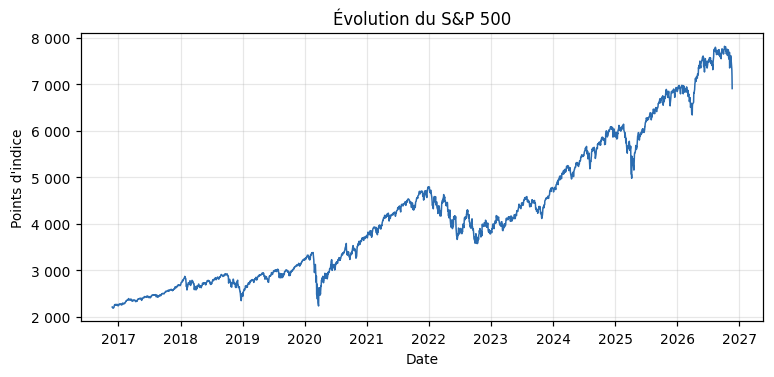

In [7]:
# Figure 1 : évolution du S&P 500
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(df.index, df['SP500'], color='#2b6cb0', lw=1)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: '{:,.0f}'.format(v).replace(',', ' ')))
ax.set_xlabel('Date'); ax.set_ylabel("Points d'indice")
ax.set_title('Évolution du S&P 500')
fig.savefig(FIGURES / 'fig1_evolution_sp500.png', dpi=200, bbox_inches='tight')
plt.show()
R['niveau_debut'], R['niveau_fin'] = float(df['SP500'].iloc[0]), float(df['SP500'].iloc[-1])

In [8]:
#@title Lecture de la figure 1 (texte généré) {display-mode: "form"}
mult = R['niveau_fin'] / R['niveau_debut']
ecrire(f"""
**Lecture de la figure 1.** L'indice passe de {fr(R['niveau_debut'], 0)} à {fr(R['niveau_fin'], 0)} points (multiplié par {fr(mult)}) entre le {R['debut']} et le {R['fin']}. La série est très clairement non stationnaire (tendance {'haussière' if mult > 1 else 'baissière'}, ruptures) : on ne modélise donc pas le niveau, mais les **rendements** logarithmiques.
""")


**Lecture de la figure 1.** L'indice passe de 2213 à 6910 points (multiplié par 3,1) entre le 25/11/2016 et le 20/11/2026. La série est très clairement non stationnaire (tendance haussière, ruptures) : on ne modélise donc pas le niveau, mais les **rendements** logarithmiques.


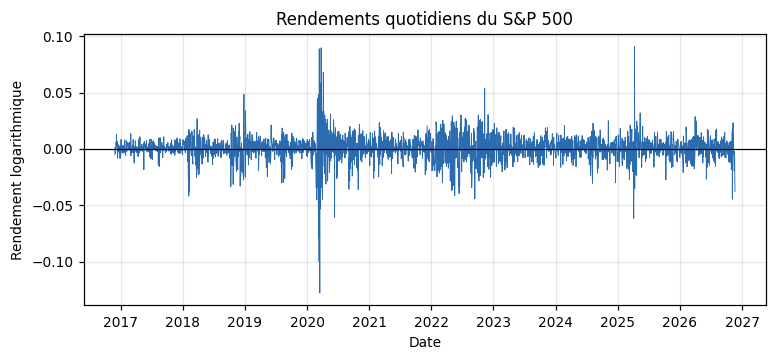

In [9]:
# Figure 2 : rendements quotidiens
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(df.index, df['return'], color='#2b6cb0', lw=0.6)
ax.axhline(0, color='black', lw=0.8)
ax.set_xlabel('Date'); ax.set_ylabel('Rendement logarithmique')
ax.set_title('Rendements quotidiens du S&P 500')
fig.savefig(FIGURES / 'fig2_rendements.png', dpi=200, bbox_inches='tight')
plt.show()

In [10]:
#@title Lecture de la figure 2 (texte généré) {display-mode: "form"}
ecrire(f"""
**Lecture de la figure 2.** Les rendements oscillent autour de zéro (moyenne {pct(float(r.mean()), 3)} par jour, écart-type {pct(float(r.std()), 2)}). Les grandes variations se regroupent en périodes agitées, notamment autour du {R['rend_min_date']} : c'est le phénomène d'amas de volatilité. Le signe de la séance suivante, lui, ressemble à un tirage presque aléatoire.
""")


**Lecture de la figure 2.** Les rendements oscillent autour de zéro (moyenne 0,045 % par jour, écart-type 1,15 %). Les grandes variations se regroupent en périodes agitées, notamment autour du 16/03/2020 : c'est le phénomène d'amas de volatilité. Le signe de la séance suivante, lui, ressemble à un tirage presque aléatoire.


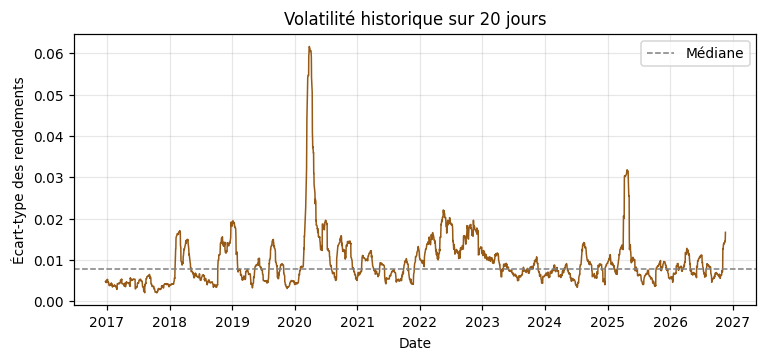

In [11]:
# Figure 3 : volatilité historique sur 20 jours
df['volatility_20'] = df['return'].rolling(20).std()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(df.index, df['volatility_20'], color='#975a16', lw=1)
ax.axhline(df['volatility_20'].median(), ls='--', color='grey', lw=1, label='Médiane')
ax.set_xlabel('Date'); ax.set_ylabel('Écart-type des rendements')
ax.set_title('Volatilité historique sur 20 jours')
ax.legend(loc='upper right')
fig.savefig(FIGURES / 'fig3_volatilite_20j.png', dpi=200, bbox_inches='tight')
plt.show()
v20 = df['volatility_20'].dropna()
R['vol20'] = {'min': float(v20.min()), 'med': float(v20.median()), 'max': float(v20.max()), 'date_max': v20.idxmax().strftime('%d/%m/%Y')}

In [12]:
#@title Lecture de la figure 3 (texte généré) {display-mode: "form"}
ecrire(f"""
**Lecture de la figure 3.** La volatilité sur 20 jours varie de {fr(R['vol20']['min'] * 100, 2)} % à {fr(R['vol20']['max'] * 100, 2)} % par jour (médiane {fr(R['vol20']['med'] * 100, 2)} %), avec un pic le {R['vol20']['date_max']}. Le marché alterne donc des **régimes** calmes et agités : les relations apprises dans un régime ne sont pas forcément valables dans un autre, ce qui motive un découpage chronologique et un diagnostic par période.
""")


**Lecture de la figure 3.** La volatilité sur 20 jours varie de 0,21 % à 6,17 % par jour (médiane 0,78 %), avec un pic le 27/03/2020. Le marché alterne donc des **régimes** calmes et agités : les relations apprises dans un régime ne sont pas forcément valables dans un autre, ce qui motive un découpage chronologique et un diagnostic par période.


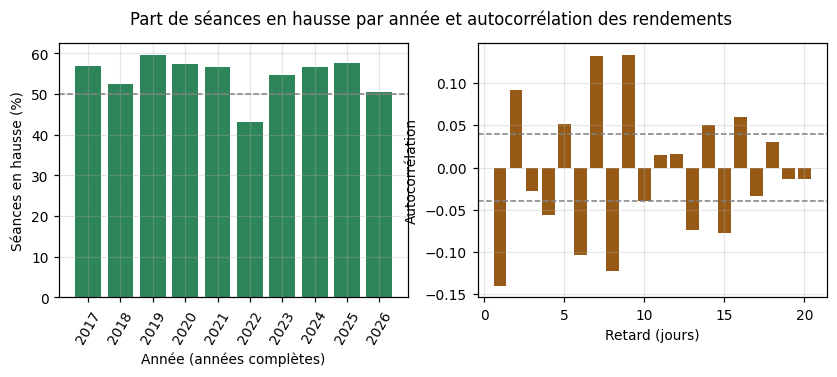

In [13]:
# Figure complémentaire : taux de hausse par année et autocorrélation des rendements
annee = (r > 0).groupby(r.index.year).agg(['mean', 'size'])
annee = annee[annee['size'] >= 100]            # on écarte les années très incomplètes
acf = pd.Series([r.autocorr(l) for l in range(1, 21)], index=range(1, 21))
bande = 1.96 / np.sqrt(len(r))
R['hausse_annuelle'] = {int(k): round(float(v) * 100, 1) for k, v in annee['mean'].items()}
R['acf'] = {'bande': float(bande), 'n_hors_bande': int((acf.abs() > bande).sum()), 'lag1': float(acf.loc[1])}
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].bar(annee.index.astype(str), annee['mean'] * 100, color='#2f855a')
axes[0].axhline(50, ls='--', color='grey', lw=1)
axes[0].set_xlabel('Année (années complètes)'); axes[0].set_ylabel('Séances en hausse (%)')
axes[0].tick_params(axis='x', rotation=60)
axes[1].bar(acf.index, acf.values, color='#975a16')
axes[1].axhline(bande, ls='--', color='grey', lw=1); axes[1].axhline(-bande, ls='--', color='grey', lw=1)
axes[1].set_xlabel('Retard (jours)'); axes[1].set_ylabel('Autocorrélation')
fig.suptitle('Part de séances en hausse par année et autocorrélation des rendements')
fig.savefig(FIGURES / 'figA_hausse_autocorrelation.png', dpi=200, bbox_inches='tight')
plt.show()

In [14]:
#@title Lecture de la figure complémentaire (texte généré) {display-mode: "form"}
h = R['hausse_annuelle']
a_min, a_max = min(h, key=h.get), max(h, key=h.get)
ecrire(f"""
**Lecture.** La part de séances en hausse varie selon l'année, de {fr(h[a_min])} % ({a_min}) à {fr(h[a_max])} % ({a_max}) : le taux de base n'est pas stable. L'autocorrélation du rendement au retard 1 vaut {fr(R['acf']['lag1'], 3)} ; sur 20 retards, {R['acf']['n_hors_bande']} retard(s) dépasse(nt) la bande de confiance à 95 % (±{fr(R['acf']['bande'], 3)}), alors qu'environ un retard sur vingt la dépasserait par pur hasard. La dépendance linéaire du signe avec le passé est donc faible, ce qui annonce une tâche difficile.
""")


**Lecture.** La part de séances en hausse varie selon l'année, de 43,0 % (2022) à 59,5 % (2019) : le taux de base n'est pas stable. L'autocorrélation du rendement au retard 1 vaut -0,140 ; sur 20 retards, 13 retard(s) dépasse(nt) la bande de confiance à 95 % (±0,039), alors qu'environ un retard sur vingt la dépasserait par pur hasard. La dépendance linéaire du signe avec le passé est donc faible, ce qui annonce une tâche difficile.


## 6. Préparation

In [15]:
# Construction des variables : uniquement à partir du passé (décalages positifs, fenêtres glissantes)
LAGS = [1, 2, 3, 5, 10, 20]
data = pd.DataFrame({'SP500': df['SP500']})
data['log_price'] = np.log(data['SP500'])
data['return'] = data['log_price'].diff()
for lag in LAGS:
    data['ret_lag_{}'.format(lag)] = data['return'].shift(lag - 1)       # ret_lag_1 = rendement du jour courant
data['volatility_5'] = data['return'].rolling(5).std()
data['volatility_20'] = data['return'].rolling(20).std()

# Cible : direction du jour suivant (utilise le futur, uniquement pour la cible)
rendement_futur = data['log_price'].shift(-1) - data['log_price']
data['target'] = np.where(rendement_futur.isna(), np.nan, (rendement_futur > 0).astype(int))

n_avant = len(data)
data = data.dropna()                                                    # début (fenêtres) et dernière ligne (cible inconnue)
R['lignes_perdues'] = int(n_avant - len(data))

VARIABLES = ['ret_lag_1', 'ret_lag_2', 'ret_lag_3', 'ret_lag_5', 'ret_lag_10', 'ret_lag_20', 'volatility_5', 'volatility_20']
X, y = data[VARIABLES], data['target'].astype(int)
R['n_modele'] = int(len(data))
R['taux_hausse'] = float(y.mean())
print('Lignes perdues (fenêtres et dernière cible) :', R['lignes_perdues'], '| lignes utilisables :', R['n_modele'])
print('Répartition de la cible :')
print(pd.DataFrame({'effectif': y.value_counts().sort_index(), 'part': y.value_counts(normalize=True).sort_index().round(3)}))

Lignes perdues (fenêtres et dernière cible) : 21 | lignes utilisables : 2490
Répartition de la cible :
        effectif   part
target                 
0           1131  0.454
1           1359  0.546


In [16]:
# Découpage chronologique : 80 % les plus anciennes séances pour l'apprentissage, 20 % les plus récentes pour le test.
# Un écart d'une séance (GAP) est retiré entre les deux : la cible du dernier jour d'apprentissage utilise le cours
# du premier jour de test.
GAP = 1
n_test = int(round(0.2 * len(data)))
X_app, X_test = X.iloc[:-(n_test + GAP)], X.iloc[-n_test:]
y_app, y_test = y.iloc[:-(n_test + GAP)], y.iloc[-n_test:]
R['n_app'], R['n_test'] = len(X_app), len(X_test)
R['taux_app'], R['taux_test'] = float(y_app.mean()), float(y_test.mean())
R['periode_app'] = [X_app.index[0].strftime('%d/%m/%Y'), X_app.index[-1].strftime('%d/%m/%Y')]
R['periode_test'] = [X_test.index[0].strftime('%d/%m/%Y'), X_test.index[-1].strftime('%d/%m/%Y')]
print('Apprentissage : {} séances ({} au {}), hausses {} | Test : {} séances ({} au {}), hausses {}'.format(
    R['n_app'], R['periode_app'][0], R['periode_app'][1], pct(R['taux_app']),
    R['n_test'], R['periode_test'][0], R['periode_test'][1], pct(R['taux_test'])))

# Vérification de l'ordre : dernières lignes d'apprentissage, ligne retirée, premières lignes de test
rang = pd.Series(np.arange(len(data)), index=data.index)
def extrait(idx, nom):
    return data.loc[idx, ['SP500', 'target']].assign(rang=rang.loc[idx], ensemble=nom)
pd.concat([extrait(X_app.index[-2:], 'apprentissage'),
           extrait(X.index[len(X_app):len(X_app) + GAP], 'écart (retiré)'),
           extrait(X_test.index[:2], 'test')])

Apprentissage : 1991 séances (23/12/2016 au 21/11/2024), hausses 54,7 % | Test : 498 séances (25/11/2024 au 19/11/2026), hausses 53,8 %


,SP500,target,rang,ensemble
Date,,,,
2024-11-20,5917.11,1.0,1989,apprentissage
2024-11-21,5948.71,1.0,1990,apprentissage
2024-11-22,5969.34,1.0,1991,écart (retiré)
2024-11-25,5987.37,1.0,1992,test
2024-11-26,6021.63,0.0,1993,test


In [17]:
# Pipelines : la standardisation est ajustée sur l'apprentissage seulement, dans chaque pli
tscv = TimeSeriesSplit(n_splits=5, gap=GAP)
plis = list(tscv.split(X_app))

pipeline_knn = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])
lr = Pipeline([('scaler', StandardScaler()), ('modele', LogisticRegression(max_iter=3000))])
print('Plis de validation (apprentissage, validation) :', [(len(a), len(v)) for a, v in plis])

Plis de validation (apprentissage, validation) : [(335, 331), (666, 331), (997, 331), (1328, 331), (1659, 331)]


**Choix de préparation.**

1. **Nettoyage :** les jours sans cotation et les doublons de date sont supprimés ; les séries sont triées par date ; aucun rendement extrême n'est retiré.
2. **Variables créées :** rendements décalés (1, 2, 3, 5, 10 et 20 jours), volatilités sur 5 et 20 jours, cible à un jour. Les premières lignes (fenêtres incomplètes) et la dernière (cible inconnue) sont retirées.
3. **Standardisation :** indispensable pour KNN, qui repose sur des distances : sans elle, les variables de plus grande amplitude domineraient. Elle est incluse dans le `Pipeline`. Aucun encodage n'est nécessaire, toutes les variables sont numériques.
4. **Découpage chronologique :** les 80 % de séances les plus anciennes servent à l'apprentissage (réglage compris), les 20 % les plus récentes au test, avec une séance d'écart. Les effectifs et les périodes sont affichés ci-dessus ; l'affichage de contrôle confirme que le test commence après l'apprentissage.

**Prévention des fuites.**

- ✔ Standardisation ajustée sur l'apprentissage seulement, dans un `Pipeline` (et donc dans chaque pli de validation).
- ✔ Découpage chronologique, sans mélange, avec une séance d'écart entre apprentissage et test ; `TimeSeriesSplit` avec `gap=1` pour la validation.
- ✔ Variables construites avec le passé seulement : décalages positifs et fenêtres glissantes se terminant au jour courant ; seul le rendement du lendemain, utilisé pour la cible, regarde vers le futur.
- ✔ Aucune variable ne contient la cible.
- ✔ Jeu de test utilisé une seule fois, à la fin.

## 7. Algorithme

**Choix.** Algorithme 9 du support : K plus proches voisins en classification (`KNeighborsClassifier` [12]). Il ne suppose aucune relation linéaire entre les rendements passés, la volatilité et la direction future, et reste simple à expliquer. La régression logistique (algorithme 8), plus simple encore, sert de comparaison.

**Principe.** KNN ne construit pas de modèle explicite : il mémorise les séances d'apprentissage. Pour une nouvelle séance décrite par le vecteur $x$ (déjà standardisé), il cherche les $k$ séances passées les plus proches au sens de la distance de Minkowski, puis prend la décision majoritaire de leurs directions [6] :

$$d_p(x, x') = \left( \sum_{j=1}^{8} |x_j - x'_j|^p \right)^{1/p}, \qquad \hat{p}(x) = \frac{\sum_{i \in N_k(x)} w_i \, y_i}{\sum_{i \in N_k(x)} w_i}, \qquad \hat{y}(x) = \mathbb{1}\left[\hat{p}(x) \ge 0{,}5\right]$$

où $N_k(x)$ est l'ensemble des $k$ voisins, $y_i \in \{0, 1\}$ la direction observée le lendemain de la séance $i$, et $w_i$ le poids du voisin : $w_i = 1$ (vote uniforme) ou $w_i = 1 / d_p(x, x_i)$ (vote pondéré par la distance). $\hat{p}(x)$ est la part de voisins pondérée qui précèdent une hausse.

**Paramètres appris :** aucun au sens strict (algorithme « paresseux ») ; seuls la moyenne et l'écart-type de chaque variable, utilisés par la standardisation, sont estimés sur l'apprentissage.

| Hyperparamètre | Rôle et effet attendu | Valeurs testées |
| --- | --- | --- |
| `n_neighbors` ($k$) | Nombre de voisins : petit, frontière irrégulière et sensible au bruit ; grand, frontière lisse mais plus grossière | 3 ; 5 ; 7 ; 9 ; 15 ; 21 |
| `weights` | Vote uniforme, ou pondéré par l'inverse de la distance (les voisins proches comptent plus) | `uniform` ; `distance` |
| `p` | Distance de Manhattan ($p = 1$) ou euclidienne ($p = 2$) | 1 ; 2 |

## 8. Protocole expérimental

In [18]:
#@title Tableau du protocole (texte généré) {display-mode: "form"}
taille_pli = len(plis[0][1])
ecrire(f"""
| Ensemble | Période ou proportion | Observations |
| --- | --- | --- |
| Apprentissage | 80 % les plus anciennes séances ({R['periode_app'][0]} au {R['periode_app'][1]}), hausses {pct(R['taux_app'])} | {R['n_app']} |
| Écart | 1 séance retirée entre apprentissage et test | {GAP} |
| Validation | `TimeSeriesSplit`, 5 plis dans l'apprentissage, `gap=1` | 5 × {taille_pli} |
| Test | 20 % les plus récentes séances ({R['periode_test'][0]} au {R['periode_test'][1]}), hausses {pct(R['taux_test'])} | {R['n_test']} |
""")


| Ensemble | Période ou proportion | Observations |
| --- | --- | --- |
| Apprentissage | 80 % les plus anciennes séances (23/12/2016 au 21/11/2024), hausses 54,7 % | 1991 |
| Écart | 1 séance retirée entre apprentissage et test | 1 |
| Validation | `TimeSeriesSplit`, 5 plis dans l'apprentissage, `gap=1` | 5 × 331 |
| Test | 20 % les plus récentes séances (25/11/2024 au 19/11/2026), hausses 53,8 % | 498 |


- **Références naïves :** classe majoritaire (`DummyClassifier`, stratégie `most_frequent` : on prédit toujours la classe la plus fréquente de l'apprentissage), tirage aléatoire stratifié (`stratified`, selon les proportions de l'apprentissage) et règle de persistance (on prédit « hausse » si le rendement du jour est positif, « pas de hausse » sinon). La meilleure des trois sur le test sert de seuil pour l'objectif : ce choix la favorise légèrement, donc la barre est volontairement exigeante.
- **Validation :** 24 configurations essayées pour KNN ($6 \times 2 \times 2$), régression logistique sans réglage.
- **Métrique principale :** *balanced accuracy*, moyenne du rappel de la classe 1 et du rappel de la classe 0 ; elle vaut 0,5 pour tout modèle qui ne distingue pas les classes [8].
- **Métriques secondaires :** *accuracy*, AUC ROC, précision, rappel et F1 de la classe « hausse ».
- **Graine aléatoire :** 42.

In [19]:
# Fabriques de prédictions : pour un pli (a = indices d'apprentissage, v = indices de validation), elles renvoient
# (prédiction 0/1, score continu)
def fab_dummy(strategie):
    def f(a, v):
        m = DummyClassifier(strategy=strategie, random_state=GRAINE).fit(X_app.iloc[a], y_app.iloc[a])
        p = m.predict(X_app.iloc[v])
        return p, p
    return f

def fab_persistance(a, v):
    p = (X_app.iloc[v]['ret_lag_1'] > 0).astype(int).to_numpy()
    return p, p

def fab_modele(modele, params=None):
    def f(a, v):
        m = clone(modele)
        if params:
            m.set_params(**params)
        m.fit(X_app.iloc[a], y_app.iloc[a])
        return m.predict(X_app.iloc[v]), m.predict_proba(X_app.iloc[v])[:, 1]
    return f

def val_plis(fabrique):
    """Balanced accuracy et AUC sur chaque pli de validation chronologique."""
    ba, auc = [], []
    for a, v in plis:
        pred, score = fabrique(a, v)
        ba.append(balanced_accuracy_score(y_app.iloc[v], pred))
        auc.append(roc_auc_score(y_app.iloc[v], score))
    return np.array(ba), np.array(auc)

# Références naïves évaluées sur les plis de validation
fabriques = {'majoritaire': fab_dummy('most_frequent'), 'aleatoire': fab_dummy('stratified'), 'persistance': fab_persistance}
R['val'], R['val_auc'] = {}, {}
for nom, fab in fabriques.items():
    ba, auc = val_plis(fab)
    R['val'][nom] = [float(ba.mean()), float(ba.std())]
    R['val_auc'][nom] = [float(auc.mean()), float(auc.std())]
    print('BA validation, {:<12} : {} ± {}'.format(nom, fr(ba.mean(), 3), fr(ba.std(), 3)))

BA validation, majoritaire  : 0,500 ± 0,000
BA validation, aleatoire    : 0,499 ± 0,026
BA validation, persistance  : 0,481 ± 0,038


In [20]:
# Recherche sur grille : 6 x 2 x 2 = 24 configurations, métrique balanced accuracy, validation chronologique
grille = {'knn__n_neighbors': [3, 5, 7, 9, 15, 21],
          'knn__weights': ['uniform', 'distance'],
          'knn__p': [1, 2]}
recherche = GridSearchCV(pipeline_knn, grille, scoring='balanced_accuracy', cv=tscv, n_jobs=-1,
                         refit=True, return_train_score=True)
recherche.fit(X_app, y_app)
res = pd.DataFrame(recherche.cv_results_)
tab = res[['param_knn__n_neighbors', 'param_knn__weights', 'param_knn__p',
           'mean_test_score', 'std_test_score', 'mean_train_score', 'rank_test_score']]
tab = tab.rename(columns={'param_knn__n_neighbors': 'n_neighbors', 'param_knn__weights': 'weights', 'param_knn__p': 'p',
                          'mean_test_score': 'BA_validation', 'std_test_score': 'ecart_type',
                          'mean_train_score': 'BA_apprentissage', 'rank_test_score': 'rang'}).round(3)
R['grille'] = tab.to_dict(orient='records')
R['meilleur'] = {k.replace('knn__', ''): v for k, v in recherche.best_params_.items()}
i = recherche.best_index_
R['val']['knn'] = [float(res.loc[i, 'mean_test_score']), float(res.loc[i, 'std_test_score'])]
params = {'knn__' + k: v for k, v in R['meilleur'].items()}
print('Meilleure configuration :', R['meilleur'])
tab.sort_values('rang')

Meilleure configuration : {'n_neighbors': 9, 'p': 2, 'weights': 'distance'}


,n_neighbors,weights,p,BA_validation,ecart_type,BA_apprentissage,rang
15,9,distance,2,0.521,0.037,1.000,1
20,21,uniform,1,0.521,0.027,0.568,2
14,9,uniform,2,0.517,0.039,0.635,3
21,21,distance,1,0.516,0.035,1.000,4
23,21,distance,2,0.513,0.018,1.000,5
22,21,uniform,2,0.512,0.017,0.583,6
19,15,distance,2,0.510,0.014,1.000,7
5,5,distance,1,0.510,0.034,1.000,8
18,15,uniform,2,0.509,0.017,0.605,9
1,3,distance,1,0.507,0.040,1.000,10


In [21]:
# Modèle de comparaison : régression logistique (sans réglage)
ba_lr, auc_lr = val_plis(fab_modele(lr))
R['val']['lr'] = [float(ba_lr.mean()), float(ba_lr.std())]
R['val_auc']['lr'] = [float(auc_lr.mean()), float(auc_lr.std())]
print('BA validation, régression logistique :', fr(ba_lr.mean(), 3), '±', fr(ba_lr.std(), 3))

BA validation, régression logistique : 0,505 ± 0,020


In [22]:
# Diagnostic des plis de validation (KNN retenu)
diag = []
for k, (a, v) in enumerate(plis, start=1):
    pred, score = fab_modele(pipeline_knn, params)(a, v)
    ba_maj = balanced_accuracy_score(y_app.iloc[v], fab_dummy('most_frequent')(a, v)[0])
    diag.append({'pli': k,
                 'debut_validation': X_app.index[v[0]].strftime('%m/%Y'),
                 'fin_validation': X_app.index[v[-1]].strftime('%m/%Y'),
                 'hausses_validation_%': round(float(y_app.iloc[v].mean() * 100), 1),
                 'BA_knn': round(float(balanced_accuracy_score(y_app.iloc[v], pred)), 3),
                 'BA_majoritaire': round(float(ba_maj), 3),
                 'volatilite_validation / apprentissage': round(float(X_app.iloc[v]['volatility_20'].mean() / X_app.iloc[a]['volatility_20'].mean()), 2)})
R['diag'] = diag
pd.DataFrame(diag)

,pli,debut_validation,fin_validation,hausses_validation_%,BA_knn,BA_majoritaire,volatilite_validation / apprentissage
0,1,04/2018,08/2019,54.1,0.460,0.5,1.42
1,2,08/2019,12/2020,58.3,0.564,0.5,2.09
2,3,12/2020,04/2022,54.4,0.538,0.5,0.92
3,4,04/2022,08/2023,47.7,0.499,0.5,1.35
4,5,08/2023,11/2024,57.1,0.546,0.5,0.75


In [23]:
#@title Lecture de la validation (texte généré) {display-mode: "form"}
meil = tab.sort_values('rang').iloc[0]
b, s = float(meil['BA_validation']), float(meil['ecart_type'])
nb_indiscernables = int((tab['BA_validation'] >= b - s).sum())
gap_train = float(tab['BA_apprentissage'].max())
d = pd.DataFrame(diag)
sur = ("Les configurations atteignent une BA d'apprentissage allant jusqu'à {} sans gain équivalent en validation (avec `weights='distance'`, chaque séance est son propre voisin, d'où une BA d'apprentissage proche de 1) : signe de surapprentissage.".format(fr(gap_train, 3))
       if gap_train - b > 0.1 else "L'écart entre la BA d'apprentissage et celle de validation reste modéré.")
ecrire(f"""
**Lecture de la validation.** Les 24 configurations ont une BA de validation comprise entre {fr(tab['BA_validation'].min(), 3)} et {fr(tab['BA_validation'].max(), 3)}, pour un écart-type de {fr(s, 3)} entre plis ; {nb_indiscernables} d'entre elles sont à moins d'un écart-type de la meilleure, donc statistiquement indiscernables. La meilleure en moyenne ({R['meilleur']['n_neighbors']} voisins, poids `{R['meilleur']['weights']}`, p = {R['meilleur']['p']}) atteint {fr(b, 3)} ; elle est retenue. {sur} Pour la référence, la classe majoritaire obtient {fr(R['val']['majoritaire'][0], 3)} et la régression logistique {fr(R['val']['lr'][0], 3)}.

**Diagnostic des plis.** La part de hausses en validation va de {fr(d['hausses_validation_%'].min())} % à {fr(d['hausses_validation_%'].max())} % selon le pli, et la BA du KNN de {fr(d['BA_knn'].min(), 3)} à {fr(d['BA_knn'].max(), 3)} : la performance dépend beaucoup de la période. La volatilité de la période de validation est de {fr(d['volatilite_validation / apprentissage'].min(), 2)} à {fr(d['volatilite_validation / apprentissage'].max(), 2)} fois celle de l'apprentissage, signe de changements de régime.
""")


**Lecture de la validation.** Les 24 configurations ont une BA de validation comprise entre 0,484 et 0,521, pour un écart-type de 0,037 entre plis ; 23 d'entre elles sont à moins d'un écart-type de la meilleure, donc statistiquement indiscernables. La meilleure en moyenne (9 voisins, poids `distance`, p = 2) atteint 0,521 ; elle est retenue. Les configurations atteignent une BA d'apprentissage allant jusqu'à 1,000 sans gain équivalent en validation (avec `weights='distance'`, chaque séance est son propre voisin, d'où une BA d'apprentissage proche de 1) : signe de surapprentissage. Pour la référence, la classe majoritaire obtient 0,500 et la régression logistique 0,505.

**Diagnostic des plis.** La part de hausses en validation va de 47,7 % à 58,3 % selon le pli, et la BA du KNN de 0,460 à 0,564 : la performance dépend beaucoup de la période. La volatilité de la période de validation est de 0,75 à 2,09 fois celle de l'apprentissage, signe de changements de régime.


## 9. Résultats

Le jeu de test est utilisé **une seule fois**, ci-dessous.

In [24]:
meilleur_knn = recherche.best_estimator_            # réajusté sur tout l'apprentissage
lr.fit(X_app, y_app)
modele_maj = DummyClassifier(strategy='most_frequent').fit(X_app, y_app)
modele_alea = DummyClassifier(strategy='stratified', random_state=GRAINE).fit(X_app, y_app)

pred = {'majoritaire': modele_maj.predict(X_test), 'aleatoire': modele_alea.predict(X_test),
        'persistance': (X_test['ret_lag_1'] > 0).astype(int).to_numpy(),
        'lr': lr.predict(X_test), 'knn': meilleur_knn.predict(X_test)}
scores = {'majoritaire': pred['majoritaire'], 'aleatoire': pred['aleatoire'], 'persistance': pred['persistance'],
          'lr': lr.predict_proba(X_test)[:, 1], 'knn': meilleur_knn.predict_proba(X_test)[:, 1]}

# Validation (AUC) du KNN retenu, pour compléter le tableau
ba_k, auc_k = val_plis(fab_modele(pipeline_knn, params))
R['val_auc']['knn'] = [float(auc_k.mean()), float(auc_k.std())]

R['test'] = {}
for nom in pred:
    R['test'][nom] = {'BA': float(balanced_accuracy_score(y_test, pred[nom])),
                      'accuracy': float(accuracy_score(y_test, pred[nom])),
                      'AUC': float(roc_auc_score(y_test, scores[nom])),
                      'precision': float(precision_score(y_test, pred[nom], zero_division=0)),
                      'rappel': float(recall_score(y_test, pred[nom], zero_division=0)),
                      'F1': float(f1_score(y_test, pred[nom], zero_division=0)),
                      'part_hausse_predite': float(np.mean(pred[nom]))}

# Marge d'incertitude de la BA sous l'hypothèse « aucune capacité de prévision »
n1 = int(y_test.sum()); n0 = int(len(y_test) - n1)
R['se0'] = float(0.25 * np.sqrt(1 / n1 + 1 / n0))
refs = {k: R['test'][k]['BA'] for k in ('majoritaire', 'aleatoire', 'persistance')}
R['meilleure_ref'] = max(refs, key=refs.get)
R['ba_ref'] = refs[R['meilleure_ref']]
R['seuil_objectif'] = R['ba_ref'] + 0.02

libelles = {'majoritaire': 'Référence : classe majoritaire', 'aleatoire': 'Référence : tirage stratifié',
            'persistance': 'Référence : persistance (signe du jour)', 'lr': 'Régression logistique (comparaison)',
            'knn': 'KNN (retenu)'}
synthese = pd.DataFrame({
    'BA validation': ['{} ± {}'.format(fr(R['val'][k][0], 3), fr(R['val'][k][1], 3)) for k in libelles],
    'BA test': [fr(R['test'][k]['BA'], 3) for k in libelles],
    'Accuracy test': [fr(R['test'][k]['accuracy'], 3) for k in libelles],
    'AUC validation': ['{} ± {}'.format(fr(R['val_auc'][k][0], 3), fr(R['val_auc'][k][1], 3)) for k in libelles],
    'AUC test': [fr(R['test'][k]['AUC'], 3) for k in libelles],
    'Précision (hausse)': [fr(R['test'][k]['precision'], 3) for k in libelles],
    'Rappel (hausse)': [fr(R['test'][k]['rappel'], 3) for k in libelles],
    'F1 (hausse)': [fr(R['test'][k]['F1'], 3) for k in libelles]},
    index=libelles.values())
synthese

,BA validation,BA test,Accuracy test,AUC validation,AUC test,Précision (hausse),Rappel (hausse),F1 (hausse)
Référence : classe majoritaire,"0,500 ± 0,000","0,500","0,538","0,500 ± 0,000","0,500","0,538","1,000","0,700"
Référence : tirage stratifié,"0,499 ± 0,026","0,461","0,464","0,499 ± 0,026","0,461","0,502","0,504","0,503"
Référence : persistance (signe du jour),"0,481 ± 0,038","0,513","0,516","0,481 ± 0,038","0,513","0,550","0,552","0,551"
Régression logistique (comparaison),"0,505 ± 0,020","0,497","0,532","0,493 ± 0,020","0,447","0,536","0,963","0,689"
KNN (retenu),"0,521 ± 0,037","0,500","0,512","0,519 ± 0,046","0,499","0,538","0,660","0,593"


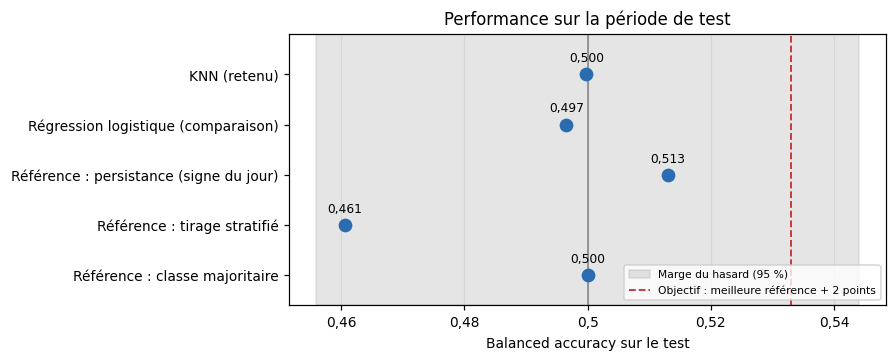

In [25]:
# Figure 4 : balanced accuracy sur le test, avec la marge d'incertitude du hasard
ordre_aff = ['majoritaire', 'aleatoire', 'persistance', 'lr', 'knn']
valeurs = [R['test'][k]['BA'] for k in ordre_aff]
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvspan(0.5 - 1.96 * R['se0'], 0.5 + 1.96 * R['se0'], color='grey', alpha=0.2, label='Marge du hasard (95 %)')
ax.axvline(0.5, color='grey', lw=1)
ax.axvline(R['seuil_objectif'], color='#c53030', ls='--', lw=1.2, label='Objectif : meilleure référence + 2 points')
ax.plot(valeurs, range(len(ordre_aff)), 'o', color='#2b6cb0', ms=8)
for i, v in enumerate(valeurs):
    ax.text(v, i + 0.25, fr(v, 3), ha='center', fontsize=8)
ax.set_yticks(range(len(ordre_aff))); ax.set_yticklabels([libelles[k] for k in ordre_aff])
ax.set_ylim(-0.6, len(ordre_aff) - 0.2)
ax.grid(axis='y', alpha=0)
ax.xaxis.set_major_formatter(virgule)
ax.set_xlabel('Balanced accuracy sur le test')
ax.set_title('Performance sur la période de test')
ax.legend(fontsize=7, loc='lower right')
fig.savefig(FIGURES / 'fig4_balanced_accuracy_test.png', dpi=200, bbox_inches='tight')
plt.show()

In [26]:
#@title Lecture des résultats (texte généré) {display-mode: "form"}
t = R['test']
ba_k, ba_r = t['knn']['BA'], R['ba_ref']
gain = (ba_k - ba_r) * 100
atteint = gain >= 2
bande = 1.96 * R['se0']
hors_hasard = abs(ba_k - 0.5) > bande
R['objectif_atteint'] = bool(atteint)
R['hors_hasard'] = bool(hors_hasard)
nom_ref = libelles[R['meilleure_ref']].replace('Référence : ', '')
ecrire(f"""
**Lecture des résultats.** Sur le test, le KNN retenu obtient une balanced accuracy de {fr(ba_k, 3)} (accuracy {fr(t['knn']['accuracy'], 3)}, AUC {fr(t['knn']['AUC'], 3)}). La meilleure référence naïve est « {nom_ref} » avec {fr(ba_r, 3)} ; la classe majoritaire vaut {fr(t['majoritaire']['BA'], 3)} et la persistance {fr(t['persistance']['BA'], 3)}. Le KNN se situe donc **{fr(abs(gain))} point(s) {'au-dessus' if gain >= 0 else 'en dessous'}** de la meilleure référence ; l'objectif de +2 points {'est atteint' if atteint else 'n’est pas atteint'}. La régression logistique obtient {fr(t['lr']['BA'], 3)}.

La figure 4 donne l'ordre de grandeur de l'incertitude : avec {n1} séances de hausse et {n0} de non-hausse dans le test, un modèle sans aucune capacité de prévision obtient une BA comprise entre {fr(0.5 - bande, 3)} et {fr(0.5 + bande, 3)} dans 95 % des cas. La BA du KNN {'sort de cette bande' if hors_hasard else 'reste dans cette bande'} : {'l’écart avec le hasard est donc peu probablement dû à la seule chance.' if hors_hasard else 'on ne peut pas distinguer ce résultat du hasard.'} Par ailleurs, le KNN prédit « hausse » pour {pct(t['knn']['part_hausse_predite'])} des séances de test, contre {pct(R['taux_test'])} de hausses réelles.
""")


**Lecture des résultats.** Sur le test, le KNN retenu obtient une balanced accuracy de 0,500 (accuracy 0,512, AUC 0,499). La meilleure référence naïve est « persistance (signe du jour) » avec 0,513 ; la classe majoritaire vaut 0,500 et la persistance 0,513. Le KNN se situe donc **1,3 point(s) en dessous** de la meilleure référence ; l'objectif de +2 points n’est pas atteint. La régression logistique obtient 0,497.

La figure 4 donne l'ordre de grandeur de l'incertitude : avec 268 séances de hausse et 230 de non-hausse dans le test, un modèle sans aucune capacité de prévision obtient une BA comprise entre 0,456 et 0,544 dans 95 % des cas. La BA du KNN reste dans cette bande : on ne peut pas distinguer ce résultat du hasard. Par ailleurs, le KNN prédit « hausse » pour 66,1 % des séances de test, contre 53,8 % de hausses réelles.


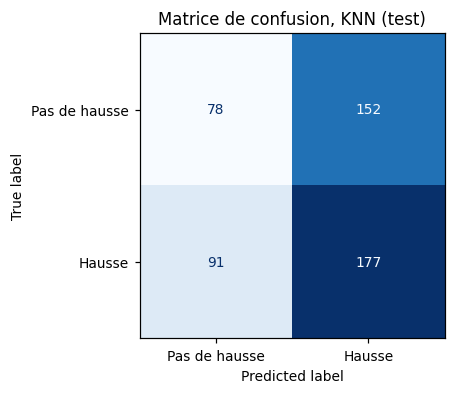

{'VN': 78, 'FP': 152, 'FN': 91, 'VP': 177}


In [27]:
# Figure 5 : matrice de confusion du KNN sur le test
cm = confusion_matrix(y_test, pred['knn'])
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Pas de hausse', 'Hausse']).plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.grid(False)
ax.set_title('Matrice de confusion, KNN (test)')
fig.savefig(FIGURES / 'fig5_matrice_confusion.png', dpi=200, bbox_inches='tight')
plt.show()
R['confusion'] = {'VN': int(cm[0, 0]), 'FP': int(cm[0, 1]), 'FN': int(cm[1, 0]), 'VP': int(cm[1, 1])}
print(R['confusion'])

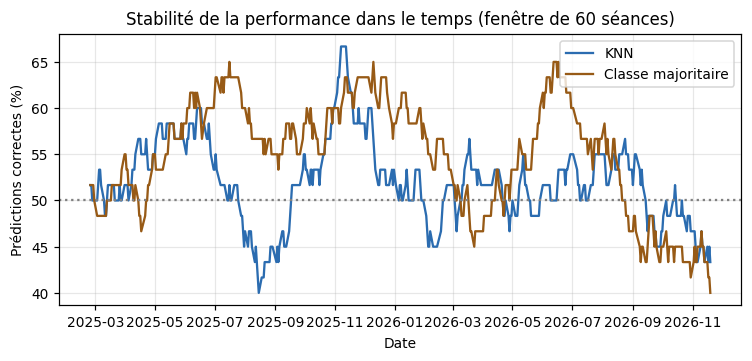

In [28]:
# Figure 6 : part de prédictions correctes sur une fenêtre glissante de 60 séances, dans le test
juste_knn = pd.Series((pred['knn'] == y_test.to_numpy()).astype(float), index=y_test.index)
juste_maj = pd.Series((pred['majoritaire'] == y_test.to_numpy()).astype(float), index=y_test.index)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(juste_knn.rolling(60).mean() * 100, color='#2b6cb0', label='KNN')
ax.plot(juste_maj.rolling(60).mean() * 100, color='#975a16', label='Classe majoritaire')
ax.axhline(50, color='grey', ls=':')
ax.set_xlabel('Date'); ax.set_ylabel('Prédictions correctes (%)')
ax.set_title('Stabilité de la performance dans le temps (fenêtre de 60 séances)')
ax.legend(loc='upper right')
fig.savefig(FIGURES / 'fig6_stabilite.png', dpi=200, bbox_inches='tight')
plt.show()

In [29]:
# Analyse des erreurs
test = data.loc[X_test.index].assign(proba=scores['knn'], pred=pred['knn'])
c = R['confusion']
moitie = len(test) // 2
def ba_sous(masque):
    sous = test[masque]
    return float(balanced_accuracy_score(sous['target'], sous['pred'])) if sous['target'].nunique() == 2 else float('nan')
R['moities'] = [ba_sous(test.index < test.index[moitie]), ba_sous(test.index >= test.index[moitie])]
seuil_vol = float(X_app['volatility_20'].median())          # médiane de l'apprentissage : pas de fuite
R['regimes'] = {'vol_basse': ba_sous(test['volatility_20'] <= seuil_vol), 'vol_haute': ba_sous(test['volatility_20'] > seuil_vol),
                'part_vol_haute': float((test['volatility_20'] > seuil_vol).mean())}
R['proba_moyenne_test'] = float(test['proba'].mean())
R['BA_app_knn'] = float(balanced_accuracy_score(y_app, meilleur_knn.predict(X_app)))
R['ratio_vol_test_app'] = float(X_test['volatility_20'].mean() / X_app['volatility_20'].mean())
print('Matrice de confusion :', c)
print('Rappel des hausses : {} | rappel des non-hausses : {}'.format(fr(c['VP'] / (c['VP'] + c['FN']), 3), fr(c['VN'] / (c['VN'] + c['FP']), 3)))
print('BA première et seconde moitié du test :', fr(R['moities'][0], 3), 'et', fr(R['moities'][1], 3))
print('BA en volatilité basse / haute (seuil = médiane de l\'apprentissage) :', fr(R['regimes']['vol_basse'], 3), '/', fr(R['regimes']['vol_haute'], 3))
print('BA apprentissage :', fr(R['BA_app_knn'], 3), '| BA test :', fr(R['test']['knn']['BA'], 3))
print('Volatilité moyenne test / apprentissage :', fr(R['ratio_vol_test_app'], 2))

Matrice de confusion : {'VN': 78, 'FP': 152, 'FN': 91, 'VP': 177}
Rappel des hausses : 0,660 | rappel des non-hausses : 0,339
BA première et seconde moitié du test : 0,508 et 0,491
BA en volatilité basse / haute (seuil = médiane de l'apprentissage) : 0,506 / 0,494
BA apprentissage : 1,000 | BA test : 0,500
Volatilité moyenne test / apprentissage : 0,94


In [30]:
#@title Analyse des erreurs (texte généré) {display-mode: "form"}
c = R['confusion']
rap1, rap0 = c['VP'] / (c['VP'] + c['FN']), c['VN'] / (c['VN'] + c['FP'])
ecrire(f"""
**Analyse des erreurs.** Le KNN commet deux types d'erreurs : prédire une hausse alors que le marché ne monte pas ({c['FP']} faux positifs) et prédire une absence de hausse alors que le marché monte ({c['FN']} faux négatifs). Il retrouve {pct(rap1)} des séances de hausse et {pct(rap0)} des séances de non-hausse ; un modèle sans information obtiendrait environ 50 % dans chaque classe. Les deux moitiés chronologiques du test donnent des BA de {fr(R['moities'][0], 3)} puis {fr(R['moities'][1], 3)}, et la BA est de {fr(R['regimes']['vol_basse'], 3)} en régime de volatilité basse contre {fr(R['regimes']['vol_haute'], 3)} en volatilité haute (seuil : médiane de l'apprentissage ; {pct(R['regimes']['part_vol_haute'], 0)} des séances de test sont en volatilité haute). La figure 6 montre que la part de prédictions correctes fluctue autour de 50 % : la direction du marché reste très difficile à anticiper.
""")


**Analyse des erreurs.** Le KNN commet deux types d'erreurs : prédire une hausse alors que le marché ne monte pas (152 faux positifs) et prédire une absence de hausse alors que le marché monte (91 faux négatifs). Il retrouve 66,0 % des séances de hausse et 33,9 % des séances de non-hausse ; un modèle sans information obtiendrait environ 50 % dans chaque classe. Les deux moitiés chronologiques du test donnent des BA de 0,508 puis 0,491, et la BA est de 0,506 en régime de volatilité basse contre 0,494 en volatilité haute (seuil : médiane de l'apprentissage ; 52 % des séances de test sont en volatilité haute). La figure 6 montre que la part de prédictions correctes fluctue autour de 50 % : la direction du marché reste très difficile à anticiper.


In [31]:
# Importance des variables par permutation (sur le test, métrique balanced accuracy)
imp = permutation_importance(meilleur_knn, X_test, y_test, scoring='balanced_accuracy', n_repeats=5,
                             random_state=GRAINE, n_jobs=-1)
importance = pd.DataFrame({'variable': X_test.columns, 'baisse_BA': imp.importances_mean, 'ecart_type': imp.importances_std})
importance = importance.sort_values('baisse_BA', ascending=False).round(4)
R['importance'] = importance.head(5).to_dict(orient='records')
importance

,variable,baisse_BA,ecart_type
4,ret_lag_10,0.0126,0.0200
2,ret_lag_3,0.0024,0.0160
1,ret_lag_2,-0.0008,0.0168
7,volatility_20,-0.0122,0.0148
6,volatility_5,-0.0136,0.0163
5,ret_lag_20,-0.0162,0.0210
3,ret_lag_5,-0.0173,0.0124
0,ret_lag_1,-0.0207,0.0105


In [32]:
#@title Importance des variables (texte généré) {display-mode: "form"}
haut = importance.iloc[0]
n_utiles = int((importance['baisse_BA'] > 2 * importance['ecart_type']).sum())
ecrire(f"""
**Importance des variables.** La permutation d'une variable fait baisser la BA de {fr(haut['baisse_BA'], 4)} au plus (`{haut['variable']}`) ; {n_utiles} variable(s) sur 8 ont une baisse supérieure à deux écarts-types. {'Aucune variable ne se détache nettement : le modèle ne s’appuie sur aucun signal stable.' if n_utiles == 0 else 'Ces variables portent l’essentiel du signal éventuel.'} Une baisse nulle ou négative signifie que la variable n'aide pas, voire gêne la prévision. Ce sont des associations, pas des causes.
""")


**Importance des variables.** La permutation d'une variable fait baisser la BA de 0,0126 au plus (`ret_lag_10`) ; 0 variable(s) sur 8 ont une baisse supérieure à deux écarts-types. Aucune variable ne se détache nettement : le modèle ne s’appuie sur aucun signal stable. Une baisse nulle ou négative signifie que la variable n'aide pas, voire gêne la prévision. Ce sont des associations, pas des causes.


In [33]:
# Illustration : 5 séances de la période de test, non vues à l'apprentissage
choix = [test['proba'].idxmax()]
choix.append(test[test['target'] == 1].drop(index=choix, errors='ignore')['proba'].idxmin())
choix.append(test[test['target'] == 0].drop(index=choix, errors='ignore')['proba'].idxmax())
choix.append(test.drop(index=choix, errors='ignore')['volatility_20'].idxmax())
choix.append(test.drop(index=choix, errors='ignore')['proba'].sub(test['proba'].median()).abs().idxmin())
illustration = test.loc[choix, ['SP500', 'return', 'volatility_20', 'proba', 'pred', 'target']].round(
    {'return': 4, 'volatility_20': 4, 'proba': 3})
illustration.insert(0, 'cas', ['probabilité de hausse la plus haute', 'hausse la plus mal anticipée',
                                'faux positif le plus marqué', 'volatilité la plus forte', 'cas médian'])
illustration

,cas,SP500,return,volatility_20,proba,pred,target
Date,,,,,,,
2025-07-01,probabilité de hausse la plus haute,6198.01,-0.0011,0.0063,1.000,1,1.0
2025-10-02,hausse la plus mal anticipée,6715.35,0.0006,0.0038,0.102,0,1.0
2026-03-02,faux positif le plus marqué,6881.62,0.0004,0.0083,1.000,1,0.0
2025-04-25,volatilité la plus forte,5525.21,0.0073,0.0318,0.546,1,1.0
2026-09-15,cas médian,7585.73,-0.0045,0.0057,0.564,1,0.0


In [34]:
#@title Exemples (texte généré) {display-mode: "form"}
ill = illustration
def verdict(l):
    return 'correcte' if l['pred'] == l['target'] else 'erronée'
l1, l2, l3 = ill.iloc[0], ill.iloc[1], ill.iloc[2]
ecrire(f"""
**Exemples.** Le {ill.index[0].strftime('%d/%m/%Y')}, le KNN donne sa plus forte probabilité de hausse ({fr(l1['proba'], 3)}) ; le marché {'monte' if l1['target'] == 1 else 'ne monte pas'} le lendemain : prédiction {verdict(l1)}. Le {ill.index[1].strftime('%d/%m/%Y')}, la hausse du lendemain était annoncée avec seulement {fr(l2['proba'], 3)} : c'est la hausse la plus mal anticipée. Le {ill.index[2].strftime('%d/%m/%Y')}, la probabilité de hausse est de {fr(l3['proba'], 3)} alors que le marché ne monte pas : c’est le faux positif le plus marqué (hors le premier exemple). Les probabilités d'un KNN ne prennent que quelques valeurs (multiples de 1/k avec un vote uniforme) et ne sont pas calibrées.
""")


**Exemples.** Le 01/07/2025, le KNN donne sa plus forte probabilité de hausse (1,000) ; le marché monte le lendemain : prédiction correcte. Le 02/10/2025, la hausse du lendemain était annoncée avec seulement 0,102 : c'est la hausse la plus mal anticipée. Le 02/03/2026, la probabilité de hausse est de 1,000 alors que le marché ne monte pas : c’est le faux positif le plus marqué (hors le premier exemple). Les probabilités d'un KNN ne prennent que quelques valeurs (multiples de 1/k avec un vote uniforme) et ne sont pas calibrées.


In [35]:
# Contrôle, NON RETENU pour l'évaluation : validation croisée aléatoire stratifiée sur tout le jeu
cv_alea = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
ctl = cross_validate(clone(pipeline_knn).set_params(**params), X, y, cv=cv_alea,
                     scoring=['balanced_accuracy', 'roc_auc'], n_jobs=-1)
R['controle_aleatoire'] = {'BA': float(ctl['test_balanced_accuracy'].mean()), 'AUC': float(ctl['test_roc_auc'].mean())}
print('Découpage aléatoire (contrôle) : BA', fr(R['controle_aleatoire']['BA'], 3), '| AUC', fr(R['controle_aleatoire']['AUC'], 3))

Découpage aléatoire (contrôle) : BA 0,509 | AUC 0,521


## 10. Discussion des résultats

In [36]:
#@title Discussion (texte généré) {display-mode: "form"}
t = R['test']
ba_k, ba_r = t['knn']['BA'], R['ba_ref']
gain = (ba_k - ba_r) * 100
bande = 1.96 * R['se0']
nom_ref = libelles[R['meilleure_ref']].replace('Référence : ', '')
bv = R['val']['knn'][0]
ctl_ba = R['controle_aleatoire']['BA']

if R['objectif_atteint'] and R['hors_hasard']:
    verdict_obj = "L'objectif est atteint et l'écart avec le hasard dépasse la marge d'incertitude."
elif R['objectif_atteint']:
    verdict_obj = "L'objectif est atteint sur le papier, mais le résultat reste dans la marge d'incertitude du hasard : il ne constitue pas une preuve de prévisibilité."
else:
    verdict_obj = "L'objectif n'est pas atteint : le KNN ne bat pas la meilleure référence naïve de deux points."

ecrire(f"""
**Réponse à l'objectif.** Le KNN obtient une balanced accuracy de {fr(ba_k, 3)} sur le test, contre {fr(ba_r, 3)} pour la meilleure référence (« {nom_ref} »), soit un écart de {fr(gain)} point(s) pour un seuil de 2 points. {verdict_obj}

**Interprétation.** La régression logistique obtient {fr(t['lr']['BA'], 3)} et le KNN {fr(ba_k, 3)} : {'les deux modèles sont proches' if abs(t['lr']['BA'] - ba_k) < 0.02 else 'les deux modèles diffèrent sensiblement'}. L'AUC du KNN vaut {fr(t['knn']['AUC'], 3)} (0,5 correspond au hasard). {'Aucune variable ne se détache nettement dans l’importance par permutation, ce qui est cohérent avec l’hypothèse de marche aléatoire [2].' if n_utiles == 0 else str(n_utiles) + ' variable(s) se détachent dans l’importance par permutation (' + ', '.join(importance[importance["baisse_BA"] > 2 * importance["ecart_type"]]["variable"]) + ') ; avec un seul jeu de test, ce signal doit être confirmé sur d’autres périodes avant d’être interprété [2].'}

**Surapprentissage et généralisation.** La BA du KNN retenu est de {fr(bv, 3)} en validation, de {fr(R['BA_app_knn'], 3)} sur l'apprentissage (surtout mécanique avec des poids par la distance : chaque point est son propre voisin) et de {fr(ba_k, 3)} sur le test. Une différence marquée entre validation et test indique que le modèle généralise difficilement ; la validation sert à choisir les paramètres, le test à mesurer la généralisation sur des séances qui n'ont jamais participé à cette sélection. Le contrôle par découpage aléatoire donne une BA de {fr(ctl_ba, 3)}, {'plus flatteuse que l’évaluation chronologique : mélanger les périodes rend les séances voisines dans le temps comparables entre apprentissage et test (volatilité et niveaux proches) et surestime la performance réelle.' if ctl_ba > ba_k + 0.01 else 'proche de celle de l’évaluation chronologique : quand les rendements sont presque aléatoires, mélanger les périodes ne gonfle pas beaucoup le score, mais cette méthode resterait inadaptée à un usage réel.'}

**Points forts et limites de KNN.** Il est simple à comprendre et ne suppose aucune relation linéaire, ce qui lui permet en principe de repérer des configurations de rendements et de volatilité déjà rencontrées. Il est en revanche sensible au nombre de voisins, à la distance et à la standardisation ; il se dégrade quand les données sont bruitées, ce qui est le cas des rendements quotidiens, et son coût de prédiction croît avec le nombre d'observations.

**Erreurs de classification.** Les faux positifs (hausse annoncée, marché qui ne monte pas) et les faux négatifs (hausse manquée) sont chacun nombreux ({R['confusion']['FP']} et {R['confusion']['FN']} dans le test) : le modèle n'évite pas durablement l'un des deux types d'erreurs.

**Risque de data snooping.** Essayer de nombreuses configurations (24 ici) sur les mêmes données peut produire un modèle adapté au passé plutôt qu'à une tendance généralisable [10]. Nous limitons ce risque en réglant les paramètres uniquement dans l'apprentissage, par validation chronologique, et en n'utilisant le test qu'une seule fois. Même ainsi, {nb_indiscernables} configurations sont indiscernables en validation : le choix de la « meilleure » est en partie dû au hasard.

**Changements de régime.** Le marché alterne des périodes de hausse, de baisse et de forte volatilité (figures 1 et 3). La volatilité moyenne du test vaut {fr(R['ratio_vol_test_app'], 2)} fois celle de l'apprentissage, et la part de hausses passe de {pct(R['taux_app'])} à {pct(R['taux_test'])}. KNN s'appuie sur la similarité avec le passé : si le régime actuel n'a pas d'équivalent dans l'apprentissage, ses voisins ne sont pas pertinents. C'est une forme de dérive conceptuelle [11].

**Comparaison avec les travaux liés.** Nos résultats {'restent proches du hasard, comme' if not R['hors_hasard'] else 'dépassent la marge du hasard, ce qui diffère de'} l'essentiel de la littérature, où la plupart des prédicteurs ne battent pas une référence naïve hors échantillon [4]. Les gains rapportés pour l'apprentissage automatique sont modestes et concernent surtout des données mensuelles très riches en variables [5] ; nous n'utilisons que 8 variables tirées des prix d'un seul indice, à la fréquence quotidienne.

**Limites et biais.** Un seul indice américain, environ dix ans de données ; une seule période de test de {R['n_test']} séances, soit environ {fr(R['n_test'] / 252)} année(s) ; la balanced accuracy ne mesure pas un gain financier (ni coûts de transaction, ni taille des mouvements, ni risque) ; la marge d'incertitude du test est de ±{fr(bande * 100)} point(s).

**Pistes d'amélioration.** (1) Ajouter des variables (volume, VIX, taux, variables macroéconomiques) et d'autres horizons de prévision. (2) Évaluer sur plusieurs périodes successives par validation *walk-forward* et corriger le risque de sélection multiple [10]. (3) Comparer à d'autres algorithmes (arbres, gradient boosting) et réentraîner sur une fenêtre glissante. (4) Traduire la prévision en stratégie et mesurer rendement, risque et coûts de transaction.
""")


**Réponse à l'objectif.** Le KNN obtient une balanced accuracy de 0,500 sur le test, contre 0,513 pour la meilleure référence (« persistance (signe du jour) »), soit un écart de -1,3 point(s) pour un seuil de 2 points. L'objectif n'est pas atteint : le KNN ne bat pas la meilleure référence naïve de deux points.

**Interprétation.** La régression logistique obtient 0,497 et le KNN 0,500 : les deux modèles sont proches. L'AUC du KNN vaut 0,499 (0,5 correspond au hasard). Aucune variable ne se détache nettement dans l’importance par permutation, ce qui est cohérent avec l’hypothèse de marche aléatoire [2].

**Surapprentissage et généralisation.** La BA du KNN retenu est de 0,521 en validation, de 1,000 sur l'apprentissage (surtout mécanique avec des poids par la distance : chaque point est son propre voisin) et de 0,500 sur le test. Une différence marquée entre validation et test indique que le modèle généralise difficilement ; la validation sert à choisir les paramètres, le test à mesurer la généralisation sur des séances qui n'ont jamais participé à cette sélection. Le contrôle par découpage aléatoire donne une BA de 0,509, proche de celle de l’évaluation chronologique : quand les rendements sont presque aléatoires, mélanger les périodes ne gonfle pas beaucoup le score, mais cette méthode resterait inadaptée à un usage réel.

**Points forts et limites de KNN.** Il est simple à comprendre et ne suppose aucune relation linéaire, ce qui lui permet en principe de repérer des configurations de rendements et de volatilité déjà rencontrées. Il est en revanche sensible au nombre de voisins, à la distance et à la standardisation ; il se dégrade quand les données sont bruitées, ce qui est le cas des rendements quotidiens, et son coût de prédiction croît avec le nombre d'observations.

**Erreurs de classification.** Les faux positifs (hausse annoncée, marché qui ne monte pas) et les faux négatifs (hausse manquée) sont chacun nombreux (152 et 91 dans le test) : le modèle n'évite pas durablement l'un des deux types d'erreurs.

**Risque de data snooping.** Essayer de nombreuses configurations (24 ici) sur les mêmes données peut produire un modèle adapté au passé plutôt qu'à une tendance généralisable [10]. Nous limitons ce risque en réglant les paramètres uniquement dans l'apprentissage, par validation chronologique, et en n'utilisant le test qu'une seule fois. Même ainsi, 23 configurations sont indiscernables en validation : le choix de la « meilleure » est en partie dû au hasard.

**Changements de régime.** Le marché alterne des périodes de hausse, de baisse et de forte volatilité (figures 1 et 3). La volatilité moyenne du test vaut 0,94 fois celle de l'apprentissage, et la part de hausses passe de 54,7 % à 53,8 %. KNN s'appuie sur la similarité avec le passé : si le régime actuel n'a pas d'équivalent dans l'apprentissage, ses voisins ne sont pas pertinents. C'est une forme de dérive conceptuelle [11].

**Comparaison avec les travaux liés.** Nos résultats restent proches du hasard, comme l'essentiel de la littérature, où la plupart des prédicteurs ne battent pas une référence naïve hors échantillon [4]. Les gains rapportés pour l'apprentissage automatique sont modestes et concernent surtout des données mensuelles très riches en variables [5] ; nous n'utilisons que 8 variables tirées des prix d'un seul indice, à la fréquence quotidienne.

**Limites et biais.** Un seul indice américain, environ dix ans de données ; une seule période de test de 498 séances, soit environ 2,0 année(s) ; la balanced accuracy ne mesure pas un gain financier (ni coûts de transaction, ni taille des mouvements, ni risque) ; la marge d'incertitude du test est de ±4,4 point(s).

**Pistes d'amélioration.** (1) Ajouter des variables (volume, VIX, taux, variables macroéconomiques) et d'autres horizons de prévision. (2) Évaluer sur plusieurs périodes successives par validation *walk-forward* et corriger le risque de sélection multiple [10]. (3) Comparer à d'autres algorithmes (arbres, gradient boosting) et réentraîner sur une fenêtre glissante. (4) Traduire la prévision en stratégie et mesurer rendement, risque et coûts de transaction.


## 11. Conclusion

In [37]:
#@title Conclusion (texte généré) {display-mode: "form"}
t = R['test']
ba_k, ba_r = t['knn']['BA'], R['ba_ref']
nom_ref = libelles[R['meilleure_ref']].replace('Référence : ', '')
if R['objectif_atteint'] and R['hors_hasard']:
    phrase = "L'objectif est atteint, avec un résultat qui dépasse la marge d'incertitude du hasard ; ce signal reste à confirmer sur d'autres périodes."
elif R['objectif_atteint']:
    phrase = "L'objectif est atteint sur le papier, mais le résultat reste dans la marge d'incertitude du hasard : il ne démontre pas que le marché soit prévisible."
else:
    phrase = "L'objectif n'est pas atteint : le KNN ne bat pas de façon convaincante la marche aléatoire, ce qui est cohérent avec la difficulté connue du problème."
ecrire(f"""
Avec les seuls rendements passés et la volatilité du S&P 500, le KNN prédit la direction du jour suivant avec une balanced accuracy de {fr(ba_k, 3)} sur la période de test, contre {fr(ba_r, 3)} pour la meilleure référence naïve (« {nom_ref} »). {phrase} Le KNN fait {'mieux' if ba_k > t['lr']['BA'] else 'pas mieux'} que la régression logistique ({fr(t['lr']['BA'], 3)}).

L'enseignement principal est méthodologique : un protocole strictement chronologique (standardisation dans un `Pipeline`, validation `TimeSeriesSplit`, test utilisé une seule fois) est plus sévère qu'un découpage aléatoire, mais seul représentatif d'un usage réel ; il évite de prendre pour un signal ce qui n'est que du bruit ou une fuite d'information. La prévision des marchés financiers reste une tâche complexe : les rendements sont difficiles à anticiper, les données sont bruitées, les régimes changent, et les performances passées ne garantissent pas les performances futures.
""")


Avec les seuls rendements passés et la volatilité du S&P 500, le KNN prédit la direction du jour suivant avec une balanced accuracy de 0,500 sur la période de test, contre 0,513 pour la meilleure référence naïve (« persistance (signe du jour) »). L'objectif n'est pas atteint : le KNN ne bat pas de façon convaincante la marche aléatoire, ce qui est cohérent avec la difficulté connue du problème. Le KNN fait mieux que la régression logistique (0,497).

L'enseignement principal est méthodologique : un protocole strictement chronologique (standardisation dans un `Pipeline`, validation `TimeSeriesSplit`, test utilisé une seule fois) est plus sévère qu'un découpage aléatoire, mais seul représentatif d'un usage réel ; il évite de prendre pour un signal ce qui n'est que du bruit ou une fuite d'information. La prévision des marchés financiers reste une tâche complexe : les rendements sont difficiles à anticiper, les données sont bruitées, les régimes changent, et les performances passées ne garantissent pas les performances futures.


## 12. Références et citations

1. « S&P 500 (SP500) », FRED, Federal Reserve Bank of St. Louis, données de S&P Dow Jones Indices LLC, https://fred.stlouisfed.org/series/SP500, consulté le 24/11/2026.
2. E. F. Fama, « Efficient capital markets: a review of theory and empirical work », *The Journal of Finance*, vol. 25, n° 2, p. 383-417, 1970.
3. A. W. Lo, A. C. MacKinlay, « Stock market prices do not follow random walks: evidence from a simple specification test », *The Review of Financial Studies*, vol. 1, n° 1, p. 41-66, 1988.
4. I. Welch, A. Goyal, « A comprehensive look at the empirical performance of equity premium prediction », *The Review of Financial Studies*, vol. 21, n° 4, p. 1455-1508, 2008.
5. S. Gu, B. Kelly, D. Xiu, « Empirical asset pricing via machine learning », *The Review of Financial Studies*, vol. 33, n° 5, p. 2223-2273, 2020.
6. T. Cover, P. Hart, « Nearest neighbor pattern classification », *IEEE Transactions on Information Theory*, vol. 13, n° 1, p. 21-27, 1967.
7. D. W. Hosmer, S. Lemeshow, R. X. Sturdivant, *Applied Logistic Regression*, 3e éd., Wiley, 2013.
8. K. H. Brodersen, C. S. Ong, K. E. Stephan, J. M. Buhmann, « The balanced accuracy and its posterior distribution », *Proceedings of the 20th International Conference on Pattern Recognition (ICPR)*, p. 3121-3124, 2010.
9. C. Bergmeir, J. M. Benítez, « On the use of cross-validation for time series predictor evaluation », *Information Sciences*, vol. 191, p. 192-213, 2012.
10. H. White, « A reality check for data snooping », *Econometrica*, vol. 68, n° 5, p. 1097-1126, 2000.
11. J. Gama, I. Žliobaitė, A. Bifet, M. Pechenizkiy, A. Bouchachia, « A survey on concept drift adaptation », *ACM Computing Surveys*, vol. 46, n° 4, article 44, 2014.
12. F. Pedregosa *et al.*, « Scikit-learn: Machine Learning in Python », *Journal of Machine Learning Research*, vol. 12, p. 2825-2830, 2011. Documentation : *K-Nearest Neighbors Classification* (https://scikit-learn.org/stable/modules/neighbors.html), *Model Selection and Grid Search* (https://scikit-learn.org/stable/modules/grid_search.html), *Classification Metrics* (https://scikit-learn.org/stable/modules/model_evaluation.html).
13. Support du cours Algorithmes de Machine Learning et TP Machine Learning (TP ML), à compléter avec le nom de l'enseignant, l'établissement et l'année universitaire.

> La référence [9] n'est pas citée dans le texte ci-dessus : si vous la gardez, citez-la dans la section 6 (validation chronologique), sinon retirez-la. **Vérifiez chaque référence avant rendu** (volumes, pages, liens) : elles sont données de mémoire par l'outil d'IA.

## 13. Annexes

### A. Reproduction

Ce notebook télécharge les données, refait toute l'analyse et enregistre ses résultats. La cellule suivante rassemble les figures, les résultats chiffrés et les données dans `projet_sp500.zip` et propose son téléchargement (dans Colab).

### B. Déclaration des outils d'IA

| Outil ou ressource | Date | Usage précis | Parties concernées | Vérification effectuée |
| --- | --- | --- | --- | --- |
| Chatgpt  | 17/11/2026 | Compréhension des étapes du projet, aide à l'écriture et à la correction du code, explications sur le prétraitement et les modèles, structuration du rapport : code, analyse et rédaction |  | À compléter par l'étudiant(e) : exécution complète, relecture des lectures générées, vérification des références en ligne |

In [38]:
# Enregistrement des résultats et archive téléchargeable
def propre(o):
    if isinstance(o, dict): return {str(k): propre(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [propre(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
with open(BASE / 'resultats.json', 'w', encoding='utf-8') as f:
    json.dump(propre(R), f, ensure_ascii=False, indent=1)
archive = shutil.make_archive('projet_sp500', 'zip', BASE)
print('Archive créée :', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Hors de Colab : récupérez le fichier', archive, 'dans le dossier courant.')

Archive créée : /content/projet_sp500.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>